In [39]:
# --- Make project imports work no matter where the notebook runs from ---
from pathlib import Path
import sys
import os

def find_project_root():
    here = Path.cwd()
    # Prefer a directory that has both 'utils' and 'models'
    for p in [here, *here.parents]:
        if (p / "utils").exists() and (p / "models").exists():
            return p
    # Fallback: look for common markers (git, requirements, pyproject)
    for p in [here, *here.parents]:
        if any((p / m).exists() for m in (".git", "requirements.txt", "pyproject.toml")):
            return p
    return here  # last resort

PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root set to:", PROJECT_ROOT)

# Optional: nice for iterative development
%load_ext autoreload
%autoreload 2


import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
import contextlib
import plotly.graph_objects as go
from torch.cuda.amp import autocast, GradScaler

from utils.reproducibility_utils import seed_everything
from utils.data_loading import load_data, load_test_data, feature_names
from utils.WeightedL1Loss import WeightedHybridLoss
from utils.LDS_FocalR_Loss import EnhancedLDS_FocalR_Loss
from utils.kaggle_metric import score

from models.lstm import LSTMModel
from models.gru import GRUModel

# Set the plotting style for better-looking visualizations
plt.style.available
plt.style.use('seaborn-v0_8')

Project root set to: /home/mdesouky/workspace/mait_g2_drift_challenge
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [40]:
CONFIG = {
    # PATHS
    'TRAIN_PATH': "../datasets_challenge/train",
    'TEST_PATH': "../datasets_challenge/test",
    'DIST_CSV': "../datasets_challenge/sideSlip_distribution.csv",
    'CHECKPOINT_NAME': "best_modelv4.pth",
    'SUBMISSION_CSV': "predictions4.csv",
    
    # REPRODUCIBILITY
    'SEED': 42,
    
    # DATA LOADING
    'TRAIN_RATIO': 0.8,
    'BATCH_SIZE': 512,
    'SEQUENCE_LENGTH': 20,
    'THRESHOLD': True,
    'THRESHOLD_VALUE': 3.0,
    'THRESHOLD_COLUMN': "vxCG",
    'COLUMNS_TO_DROP': ["sideSlip", "vyCG", "time", "longitude", "latitude"],
    'TARGET': "sideSlip",
    'SCALING': True,
    
    # MODEL ARCHITECTURE 
    'MODEL_TYPE': 'LSTM',
    'RNN_UNITS': 256,          
    'FC_UNITS': 256,        
    'NUM_LAYERS': 4,           
    'DROPOUT': [0.2, 0.15, 0.1], 
    'USE_BATCH_NORM': True,
    
    # LOSS CONFIGURATION
    'LOSS_TYPE': 'LDS_FocalR',  # 'WeightedHybrid' or 'LDS_FocalR'
    'LOSS_THRESHOLDS': (0.1, 0.4),
    'LOSS_WEIGHTS': (2.4, 1.4, 2.0),  # 🔧 CONSERVATIVE: Revert to iter3 base + small increment (2.2→2.4)
    'USE_HUBER': True,
    'HUBER_BETA': 0.08,  # 🔧 RESTORED: Back to working value (was 0.06)
    
    # LDS & FOCAL PARAMETERS
    'LDS_KERNEL': 'gaussian',
    'LDS_KS': 7,  # 🔧 RESTORED: Back to working value (was 5) - proper smoothing
    'LDS_SIGMA': 1.3,  # 🔧 RESTORED: Back to working value (was 0.8) - CRITICAL for generalization
    'FOCAL_GAMMA': 0.5,  # 🔧 RESTORED: Back to working value (was 0.3) - proper hard example focus
    'NUM_BINS': 100,
    
    # OPTIMIZER 
    'LEARNING_RATE': 8e-4,  # ✅ Lower LR for stability
    'WEIGHT_DECAY': 6e-4,  # ✅ Stronger regularization
    'BETAS': (0.9, 0.999),
    'MAX_GRAD_NORM': 1.0,     
    
    # SCHEDULER
    'SCHEDULER_T_MAX': 300,
    'SCHEDULER_ETA_MIN': 1e-6,
    
    # TRAINING 
    'NUM_EPOCHS': 300,         
    'EARLY_STOP_PATIENCE': 300, 
    'USE_AMP': True,
    'EMA_DECAY': 0.995,        
    
    # CHALLENGE CONSTRAINTS
    'MANY_SHOT_CONSTRAINT': 0.2,
    'FEW_SHOT_TARGET': 0.3,
    
    # VISUALIZATION
    'FIG_SIZE': (14, 8),
    'PLOTLY_WIDTH': 1200,
    'PLOTLY_HEIGHT': 500,
}

print("="*80)
print("CONFIGURATION LOADED - CORRECTED (Revert Overfitting)")
print("="*80)
print(f"🔧 STRATEGY: Reverted to iteration 3 + small many-shot increment (2.2→2.4)")
print(f"   Previous test result: 0.209° → Target: <0.200°")
print("="*80)
print(f"Model: {CONFIG['MODEL_TYPE']} | RNN Units: {CONFIG['RNN_UNITS']} | Layers: {CONFIG['NUM_LAYERS']}")
print(f"Loss: {CONFIG['LOSS_TYPE']} | Batch Size: {CONFIG['BATCH_SIZE']}")
print(f"Loss Weights: {CONFIG['LOSS_WEIGHTS']} (Many +0.2, Medium, Few RESTORED)")
print(f"LDS: kernel={CONFIG['LDS_KERNEL']}, ks={CONFIG['LDS_KS']}, sigma={CONFIG['LDS_SIGMA']} (RESTORED)")
print(f"Focal: gamma={CONFIG['FOCAL_GAMMA']} (RESTORED) | Huber: beta={CONFIG['HUBER_BETA']} (RESTORED)")
print(f"LR: {CONFIG['LEARNING_RATE']:.1e} | Weight Decay: {CONFIG['WEIGHT_DECAY']:.1e}")
print(f"Epochs: {CONFIG['NUM_EPOCHS']} | EMA Decay: {CONFIG['EMA_DECAY']}")
print(f"Constraints: Many ≤ {CONFIG['MANY_SHOT_CONSTRAINT']}° | Few Target: {CONFIG['FEW_SHOT_TARGET']}°")
print("="*80)
print(f"⚠️  Lesson: Changing 5 parameters at once caused overfitting!")
print(f"   Val-Test gap: 0.021° → 0.049° (doubled) when we disabled smoothing")
print("="*80)


CONFIGURATION LOADED - CORRECTED (Revert Overfitting)
🔧 STRATEGY: Reverted to iteration 3 + small many-shot increment (2.2→2.4)
   Previous test result: 0.209° → Target: <0.200°
Model: LSTM | RNN Units: 256 | Layers: 4
Loss: LDS_FocalR | Batch Size: 512
Loss Weights: (2.4, 1.4, 2.0) (Many +0.2, Medium, Few RESTORED)
LDS: kernel=gaussian, ks=7, sigma=1.3 (RESTORED)
Focal: gamma=0.5 (RESTORED) | Huber: beta=0.08 (RESTORED)
LR: 8.0e-04 | Weight Decay: 6.0e-04
Epochs: 300 | EMA Decay: 0.995
Constraints: Many ≤ 0.2° | Few Target: 0.3°
⚠️  Lesson: Changing 5 parameters at once caused overfitting!
   Val-Test gap: 0.021° → 0.049° (doubled) when we disabled smoothing


In [41]:
# filepath: notebooks/task2v3.ipynb
seed_everything(CONFIG['SEED'])
print(f"✓ Random seed set to {CONFIG['SEED']}")

✓ Random seed set to 42


In [42]:
# ============================================================================
# CONFIG VALIDATOR
# ============================================================================

def validate_config(config):
    """Validate configuration for constraint-aware training"""
    warnings = []
    recommendations = []
    
    # Check loss weights
    many_weight, med_weight, few_weight = config['LOSS_WEIGHTS']
    
    if many_weight < 1.0:
        warnings.append(f"⚠️  Many-shot weight ({many_weight}) < 1.0 may fail constraint")
        recommendations.append("   → Increase to at least 1.2")
    
    if few_weight / many_weight > 3.0:
        warnings.append(f"⚠️  Few/Many weight ratio ({few_weight/many_weight:.1f}x) very high")
        recommendations.append("   → Consider reducing to < 2.5x for balance")
    
    # Check LDS/Focal balance
    if config['FOCAL_GAMMA'] > 1.0 and config['LDS_SIGMA'] > 2.0:
        warnings.append(f"⚠️  High focal_gamma ({config['FOCAL_GAMMA']}) + high sigma ({config['LDS_SIGMA']})")
        recommendations.append("   → May over-focus on tail, hurting many-shot")
    
    # Check learning rate
    if config['LEARNING_RATE'] >= 1e-3:
        warnings.append(f"⚠️  High learning rate ({config['LEARNING_RATE']:.1e})")
        recommendations.append("   → Consider 8e-4 or lower for stable convergence")
    
    # Print results
    print(f"\n{'='*80}")
    print(f"CONFIG VALIDATION")
    print(f"{'='*80}")
    
    if not warnings:
        print("✅ Configuration looks good for constraint-aware training!")
    else:
        print(f"Found {len(warnings)} potential issues:\n")
        for w, r in zip(warnings, recommendations):
            print(w)
            print(r)
    
    print(f"\n📋 KEY SETTINGS:")
    print(f"   Loss Weights: {config['LOSS_WEIGHTS']}")
    print(f"   Ratio (Few/Many): {few_weight/many_weight:.2f}x")
    print(f"   LDS: sigma={config['LDS_SIGMA']}, ks={config['LDS_KS']}")
    print(f"   Focal: gamma={config['FOCAL_GAMMA']}")
    print(f"   Learning Rate: {config['LEARNING_RATE']:.1e}")
    print(f"   Constraint: Many ≤ {config['MANY_SHOT_CONSTRAINT']}°")
    print(f"{'='*80}\n")

# Run validation
validate_config(CONFIG)



CONFIG VALIDATION
✅ Configuration looks good for constraint-aware training!

📋 KEY SETTINGS:
   Loss Weights: (2.4, 1.4, 2.0)
   Ratio (Few/Many): 0.83x
   LDS: sigma=1.3, ks=7
   Focal: gamma=0.5
   Learning Rate: 8.0e-04
   Constraint: Many ≤ 0.2°



In [43]:

print(f"\nLoading training data from: {CONFIG['TRAIN_PATH']}")
train_dataloader, val_dataloader, pipeline = load_data(
    train_path=CONFIG['TRAIN_PATH'],
    train_ratio=CONFIG['TRAIN_RATIO'],
    batchsize=CONFIG['BATCH_SIZE'],
    columns_to_drop=CONFIG['COLUMNS_TO_DROP'],
    sequence_length=CONFIG['SEQUENCE_LENGTH'],
    threshold=CONFIG['THRESHOLD'],
    threshold_value=CONFIG['THRESHOLD_VALUE'],
    threshold_column=CONFIG['THRESHOLD_COLUMN'],
    target=CONFIG['TARGET'],
    scaling=CONFIG['SCALING'],
    seed=CONFIG['SEED'],
)

print(f"✓ Training batches: {len(train_dataloader)}")
print(f"✓ Validation batches: {len(val_dataloader)}")


Loading training data from: ../datasets_challenge/train
../datasets_challenge/train/train_part_001.csv
../datasets_challenge/train/train_part_002.csv
../datasets_challenge/train/train_part_003.csv
../datasets_challenge/train/train_part_002.csv
../datasets_challenge/train/train_part_003.csv
../datasets_challenge/train/train_part_004.csv
../datasets_challenge/train/train_part_004.csv
../datasets_challenge/train/train_part_005.csv
../datasets_challenge/train/train_part_006.csv
../datasets_challenge/train/train_part_005.csv
../datasets_challenge/train/train_part_006.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_011.csv
../

In [44]:

all_train_targets = []
for i in range(len(train_dataloader.dataset)):
    _, y = train_dataloader.dataset[i]
    all_train_targets.append(y.item())

y_train_np = np.array(all_train_targets)

print(f"\n📊 TRAINING DATA:")
print(f"   Total samples: {len(y_train_np):,}")
print(f"   Mean: {y_train_np.mean():.4f}° | Std: {y_train_np.std():.4f}°")
print(f"   Range: [{y_train_np.min():.4f}°, {y_train_np.max():.4f}°]")

# Load CSV for bucket evaluation
dist_df = pd.read_csv(CONFIG['DIST_CSV'])
shot_band_mapping = dist_df.set_index("sideSlip")["band"].to_dict()

y_train_rounded = np.round(y_train_np, 1)
bands = pd.Series(y_train_rounded).map(shot_band_mapping).fillna("unknown")
band_counts = bands.value_counts()

print(f"\n📈 SHOT BAND DISTRIBUTION:")
for band in ['many', 'medium', 'few']:
    if band in band_counts.index:
        count = band_counts[band]
        pct = count / len(y_train_np) * 100
        print(f"   {band.capitalize():8s}: {count:7,} ({pct:5.2f}%)")

print(f"\n⚠️  Imbalance ratio (Many/Few): {band_counts.get('many', 0) / max(1, band_counts.get('few', 1)):.1f}x\n")


📊 TRAINING DATA:
   Total samples: 109,665
   Mean: 0.0292° | Std: 1.4141°
   Range: [-13.9700°, 11.6500°]

📈 SHOT BAND DISTRIBUTION:
   Many    :  99,951 (91.14%)
   Medium  :   7,632 ( 6.96%)
   Few     :   2,082 ( 1.90%)

⚠️  Imbalance ratio (Many/Few): 48.0x



In [45]:
# ============================================================================
# MODEL & LOSS SETUP
# ============================================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"DEVICE: {device}")
if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}\n")

# AMP setup
if torch.cuda.is_available():
    amp_device_type = "cuda"
    prefer_bf16 = True
    amp_dtype = torch.bfloat16 if (prefer_bf16 and torch.cuda.is_bf16_supported()) else torch.float16
    scaler = torch.amp.GradScaler(amp_device_type, enabled=CONFIG['USE_AMP'])
else:
    amp_device_type = None
    amp_dtype = None
    scaler = torch.amp.GradScaler("cuda", enabled=False)

def autocast_ctx():
    if amp_device_type is None or not CONFIG['USE_AMP']:
        return contextlib.nullcontext()
    return torch.amp.autocast(device_type=amp_device_type, dtype=amp_dtype, enabled=True)

# Get input size from data
X_sample, _ = next(iter(train_dataloader))
input_size = X_sample.shape[2]

# Create model
model = LSTMModel(
    input_size=input_size,
    output_size=1,
    rnn_units=CONFIG['RNN_UNITS'],
    fc_units=CONFIG['FC_UNITS'],
    dropout=CONFIG['DROPOUT'],
    num_layers=CONFIG['NUM_LAYERS'],
    use_batch_norm=CONFIG['USE_BATCH_NORM']
).to(device)

# Create loss function
if CONFIG['LOSS_TYPE'] == 'WeightedHybrid':
    criterion = WeightedHybridLoss(
        thresholds=CONFIG['LOSS_THRESHOLDS'],
        weights=CONFIG['LOSS_WEIGHTS'],
        use_huber=CONFIG['USE_HUBER'],
        huber_beta=CONFIG['HUBER_BETA'],
        scaler_y=None,
        target_is_scaled=False
    )
    print(f"✓ Loss: WeightedHybridLoss")
    print(f"  Thresholds: {CONFIG['LOSS_THRESHOLDS']}")
    print(f"  Weights: {CONFIG['LOSS_WEIGHTS']}")
    print(f"  Huber: {CONFIG['USE_HUBER']} (beta={CONFIG['HUBER_BETA']})")
else:
    criterion = EnhancedLDS_FocalR_Loss(
        train_targets=y_train_np,
        bucket_weights=CONFIG['LOSS_WEIGHTS'],
        lds_kernel=CONFIG['LDS_KERNEL'],
        lds_ks=CONFIG['LDS_KS'],
        lds_sigma=CONFIG['LDS_SIGMA'],
        focal_gamma=CONFIG['FOCAL_GAMMA'],
        use_huber=CONFIG['USE_HUBER'],
        huber_beta=CONFIG['HUBER_BETA'],
        num_bins=CONFIG['NUM_BINS'],
        dist_csv_path=CONFIG['DIST_CSV']
    ).to(device)
    print(f"✓ Loss: EnhancedLDS_FocalR_Loss")
    print(f"  Bucket Weights: {CONFIG['LOSS_WEIGHTS']} (Many, Medium, Few)")
    print(f"  LDS: kernel={CONFIG['LDS_KERNEL']}, ks={CONFIG['LDS_KS']}, sigma={CONFIG['LDS_SIGMA']}")
    print(f"  Focal: gamma={CONFIG['FOCAL_GAMMA']}")
    print(f"  Huber: {CONFIG['USE_HUBER']} (beta={CONFIG['HUBER_BETA']})")
    print(f"  Bins: {CONFIG['NUM_BINS']}")

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\n{'='*70}")
print(f"MODEL: {CONFIG['MODEL_TYPE']}")
print(f"{'='*70}")
print(f"Parameters: {total_params:,} ({trainable_params:,} trainable)")
print(f"Size: {total_params * 4 / 1024**2:.2f} MB")
print(f"Architecture:")
print(f"  - Input Size: {input_size}")
print(f"  - RNN Units: {CONFIG['RNN_UNITS']}")
print(f"  - FC Units: {CONFIG['FC_UNITS']}")
print(f"  - Layers: {CONFIG['NUM_LAYERS']}")
print(f"  - Dropout: {CONFIG['DROPOUT']}")
print(f"  - Batch Norm: {CONFIG['USE_BATCH_NORM']}")
print(f"{'='*70}\n")


DEVICE: cuda
GPU: NVIDIA RTX A4000


[EnhancedLDS+FocalR Loss - CSV-Aligned Configuration]
Loaded 234 band definitions from CSV
Approximate boundaries (max |sideslip| per band):
  Many-shot:   <= 2.4000 degrees
  Medium-shot: <= 5.0000 degrees
Data distribution:
  Many:    99951 (91.14%)
  Medium:   7632 ( 6.96%)
  Few:      2082 ( 1.90%)
Bucket weights: 2.4 / 1.4 / 2.0
Focal gamma: 0.5 | Huber beta: 0.08
LDS: kernel=gaussian, sigma=1.3

✓ Loss: EnhancedLDS_FocalR_Loss
  Bucket Weights: (2.4, 1.4, 2.0) (Many, Medium, Few)
  LDS: kernel=gaussian, ks=7, sigma=1.3
  Focal: gamma=0.5
  Huber: True (beta=0.08)
  Bins: 100

MODEL: LSTM
Parameters: 1,965,101 (1,965,101 trainable)
Size: 7.50 MB
Architecture:
  - Input Size: 22
  - RNN Units: 256
  - FC Units: 256
  - Layers: 4
  - Dropout: [0.2, 0.15, 0.1]
  - Batch Norm: True


[EnhancedLDS+FocalR Loss - CSV-Aligned Configuration]
Loaded 234 band definitions from CSV
Approximate boundaries (max |sideslip| per band):
  Many-shot:   <= 2.4000 d

In [46]:
# ============================================================================
# TRAINING SETUP (Adapted from task_01v6)
# ============================================================================

# Optimizer & Scheduler
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CONFIG['LEARNING_RATE'],
    weight_decay=CONFIG['WEIGHT_DECAY'],
    betas=CONFIG['BETAS']
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=CONFIG['SCHEDULER_T_MAX'],
    eta_min=CONFIG['SCHEDULER_ETA_MIN']
)

print(f"✓ Optimizer: AdamW (lr={CONFIG['LEARNING_RATE']:.1e}, wd={CONFIG['WEIGHT_DECAY']:.1e})")
print(f"✓ Scheduler: CosineAnnealingLR (T_max={CONFIG['SCHEDULER_T_MAX']}, eta_min={CONFIG['SCHEDULER_ETA_MIN']:.1e})")

# ✅ NEW: EMA (Exponential Moving Average) from task_01v6
ema_params = [p.detach().clone() for p in model.parameters()]

def ema_update(model_params, ema_params, decay):
    """Update EMA parameters"""
    for p, e in zip(model_params, ema_params):
        e.mul_(decay).add_(p.detach(), alpha=1.0 - decay)

@torch.no_grad()
def load_params_(model_params, src_params):
    """Load parameters from source"""
    for p, s in zip(model_params, src_params):
        p.copy_(s)

print(f"✓ EMA: Enabled (decay={CONFIG['EMA_DECAY']})")
print(f"✓ Gradient Clipping: max_norm={CONFIG['MAX_GRAD_NORM']}")

# Training state
train_curve, val_curve = [], []
train_mae_curve, val_mae_curve = [], []
bucket_many, bucket_medium, bucket_few = [], [], []
learning_rate_curve = []

best_loss = float("inf")
best_epoch = -1
epochs_no_improve = 0

print(f"\n🎯 TRAINING STRATEGY:")
print(f"   Evaluate BOTH live weights and EMA")
print(f"   Save best performer (live or EMA)")
print(f"   Constraint: Many-shot MAE ≤ {CONFIG['MANY_SHOT_CONSTRAINT']:.2f}°")
print(f"   Early stop after {CONFIG['EARLY_STOP_PATIENCE']} epochs without improvement\n")

✓ Optimizer: AdamW (lr=8.0e-04, wd=6.0e-04)
✓ Scheduler: CosineAnnealingLR (T_max=300, eta_min=1.0e-06)
✓ EMA: Enabled (decay=0.995)
✓ Gradient Clipping: max_norm=1.0

🎯 TRAINING STRATEGY:
   Evaluate BOTH live weights and EMA
   Save best performer (live or EMA)
   Constraint: Many-shot MAE ≤ 0.20°
   Early stop after 300 epochs without improvement



In [47]:
# ============================================================================
# TRAINING LOOP (Adapted from task_01v6 with EMA and dual evaluation)
# ============================================================================

for epoch in range(CONFIG['NUM_EPOCHS']):
    # =============== TRAINING ===============
    model.train()
    running_loss, running_mae = 0.0, 0.0
    num_train_batches = len(train_dataloader)

    for step, (xb, yb) in enumerate(train_dataloader):
        xb = xb.to(device, non_blocking=True).float()
        yb = yb.to(device, non_blocking=True).float().reshape(-1, 1)

        optimizer.zero_grad(set_to_none=True)
        
        # Forward pass with AMP
        with autocast_ctx():
            pred = model(xb)
            total_loss = criterion(pred, yb)
        
        # Backward pass with gradient clipping
        scaler.scale(total_loss).backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG['MAX_GRAD_NORM'])
        scaler.step(optimizer)
        scaler.update()

        # ✅ EMA update per batch
        ema_update(model.parameters(), ema_params, CONFIG['EMA_DECAY'])

        running_loss += total_loss.item()
        running_mae += (pred - yb).abs().mean().item()

    avg_train_loss = running_loss / num_train_batches
    avg_train_mae = running_mae / num_train_batches
    train_curve.append(avg_train_loss)
    train_mae_curve.append(avg_train_mae)

    # =============== VALIDATION (Dual Evaluation: Live vs EMA) ===============
    model.eval()
    
    def _evaluate(current_params):
        """Evaluate with specific parameters"""
        snapshot = [p.detach().clone() for p in model.parameters()]
        load_params_(model.parameters(), current_params)
        
        running_vloss, running_vmae = 0.0, 0.0
        all_val_preds, all_val_targets = [], []
        num_val_batches = len(val_dataloader)
        
        with torch.no_grad():
            for xv, yv in val_dataloader:
                xv = xv.to(device, non_blocking=True).float()
                yv = yv.to(device, non_blocking=True).float().reshape(-1, 1)
                
                with autocast_ctx():
                    pred_val = model(xv)
                    total_loss_val = criterion(pred_val, yv)
                
                running_vloss += total_loss_val.item()
                running_vmae += (pred_val - yv).abs().mean().item()
                all_val_preds.append(pred_val.cpu())
                all_val_targets.append(yv.cpu())
        
        # Compute bucket metrics
        all_val_preds = torch.cat(all_val_preds, dim=0).to(device)
        all_val_targets = torch.cat(all_val_targets, dim=0).to(device)
        
        if CONFIG['LOSS_TYPE'] == 'WeightedHybrid':
            bucket_stats = criterion.bucket_mae(all_val_preds.squeeze(-1), all_val_targets.squeeze(-1))
        else:
            bucket_stats = criterion.bucket_metrics(all_val_preds, all_val_targets)
        
        avg_vloss = running_vloss / num_val_batches
        avg_vmae = running_vmae / num_val_batches
        
        # Restore original params
        load_params_(model.parameters(), snapshot)
        return avg_vloss, avg_vmae, bucket_stats
    
    # Evaluate both live and EMA weights
    live_params = [p.detach().clone() for p in model.parameters()]
    vloss_live, vmae_live, buckets_live = _evaluate(live_params)
    vloss_ema, vmae_ema, buckets_ema = _evaluate(ema_params)
    
    # Choose better performer
    if vloss_ema <= vloss_live:
        best_view = "EMA"
        best_vloss, best_vmae = vloss_ema, vmae_ema
        best_buckets = buckets_ema
        best_params = [p.detach().clone() for p in ema_params]
    else:
        best_view = "LIVE"
        best_vloss, best_vmae = vloss_live, vmae_live
        best_buckets = buckets_live
        best_params = live_params
    
    val_curve.append(best_vloss)
    val_mae_curve.append(best_vmae)
    
    # Extract bucket MAE
    if CONFIG['LOSS_TYPE'] == 'WeightedHybrid':
        many_mae = best_buckets['mae_b0']
        med_mae = best_buckets['mae_b1']
        few_mae = best_buckets['mae_b2']
    else:
        many_mae = best_buckets['mae_many']
        med_mae = best_buckets['mae_medium']
        few_mae = best_buckets['mae_few']
    
    bucket_many.append(many_mae)
    bucket_medium.append(med_mae)
    bucket_few.append(few_mae)
    
    # Step scheduler
    current_lr = optimizer.param_groups[0]['lr']
    learning_rate_curve.append(current_lr)
    scheduler.step()

    # =============== LOGGING ===============
    print(f"Epoch {epoch+1:3d}/{CONFIG['NUM_EPOCHS']} | "
          f"TrL: {avg_train_loss:.5f} | VaL: {best_vloss:.5f} | "
          f"TrMAE: {avg_train_mae:.5f} | VaMAE: {best_vmae:.5f} | "
          f"Many: {many_mae:.4f} | Med: {med_mae:.4f} | Few: {few_mae:.4f} | "
          f"LR: {current_lr:.6f} | {best_view}", end="")

    # =============== CHECKPOINTING ===============
    improved = best_vloss < best_loss - 1e-9
    
    if improved:
        best_loss = best_vloss
        best_epoch = epoch
        epochs_no_improve = 0
        
        # Save checkpoint with best params (EMA or live)
        torch.save({
            'epoch': epoch,
            'model_type': CONFIG['MODEL_TYPE'],
            'model_state_dict': model.state_dict(),  # Will be overwritten with best_params
            'best_params': best_params,  # Store the actual best params
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'train_loss': avg_train_loss,
            'val_loss': best_vloss,
            'train_mae': avg_train_mae,
            'val_mae': best_vmae,
            'bucket_stats': best_buckets,
            'many_mae': many_mae,
            'few_mae': few_mae,
            'best_view': best_view,
            'config': CONFIG
        }, CONFIG['CHECKPOINT_NAME'])
        
        print(f" ✅ BEST ({best_view})")
    else:
        epochs_no_improve += 1
        if epochs_no_improve > CONFIG['EARLY_STOP_PATIENCE']:
            print(f"\n\n{'='*80}")
            print(f"⏹ Early stopping at epoch {epoch+1} (best: epoch {best_epoch+1})")
            print(f"{'='*80}")
            break
        else:
            print("")

print(f"\n{'='*80}")
print(f"✓ TRAINING COMPLETE")
print(f"  Best Epoch: {best_epoch+1}/{len(train_curve)}")
print(f"  Best Val Loss: {best_loss:.5f}")
if best_epoch >= 0:
    print(f"  Bucket MAE: Many={bucket_many[best_epoch]:.5f} | "
          f"Med={bucket_medium[best_epoch]:.5f} | Few={bucket_few[best_epoch]:.5f}")
print(f"{'='*80}\n")

# =============== LOAD BEST CHECKPOINT ===============
checkpoint = torch.load(CONFIG['CHECKPOINT_NAME'], map_location=device)

# Load the best params (EMA or live)
if 'best_params' in checkpoint:
    state_dict = model.state_dict()
    named_params = [n for n, _ in model.named_parameters()]
    restored = {name: tensor.to(device) for name, tensor in zip(named_params, checkpoint['best_params'])}
    state_dict.update(restored)
    model.load_state_dict(state_dict)
else:
    model.load_state_dict(checkpoint['model_state_dict'])

model.to(device).eval()

print(f"✓ Best model loaded: Epoch {checkpoint['epoch']+1}")
print(f"  View: {checkpoint.get('best_view', 'N/A')}")
print(f"  Val Loss: {checkpoint['val_loss']:.5f} | Val MAE: {checkpoint['val_mae']:.5f}")
print(f"  Many: {checkpoint['many_mae']:.4f}° | Few: {checkpoint['few_mae']:.4f}°\n")

Epoch   1/300 | TrL: 1.80485 | VaL: 1.56786 | TrMAE: 0.99794 | VaMAE: 1.11618 | Many: 1.1333 | Med: 0.7817 | Few: 1.4978 | LR: 0.000800 | LIVE ✅ BEST (LIVE)
Epoch   2/300 | TrL: 1.60442 | VaL: 2.00188 | TrMAE: 0.85404 | VaMAE: 1.31400 | Many: 1.2810 | Med: 1.4664 | Few: 2.3217 | LR: 0.000800 | LIVE
Epoch   2/300 | TrL: 1.60442 | VaL: 2.00188 | TrMAE: 0.85404 | VaMAE: 1.31400 | Many: 1.2810 | Med: 1.4664 | Few: 2.3217 | LR: 0.000800 | LIVE
Epoch   3/300 | TrL: 1.36025 | VaL: 1.15198 | TrMAE: 0.73849 | VaMAE: 0.72695 | Many: 0.7101 | Med: 0.8461 | Few: 1.1033 | LR: 0.000800 | LIVE ✅ BEST (LIVE)
Epoch   3/300 | TrL: 1.36025 | VaL: 1.15198 | TrMAE: 0.73849 | VaMAE: 0.72695 | Many: 0.7101 | Med: 0.8461 | Few: 1.1033 | LR: 0.000800 | LIVE ✅ BEST (LIVE)
Epoch   4/300 | TrL: 1.27356 | VaL: 1.71330 | TrMAE: 0.66614 | VaMAE: 0.44586 | Many: 0.3710 | Med: 1.0806 | Few: 1.7389 | LR: 0.000800 | EMA
Epoch   4/300 | TrL: 1.27356 | VaL: 1.71330 | TrMAE: 0.66614 | VaMAE: 0.44586 | Many: 0.3710 | Med: 1


CONSTRAINT-AWARE ANALYSIS
✅ Found 136 epochs meeting constraint (Many ≤ 0.2°)

🏆 BEST VALID SOLUTION:
   Epoch: 261
   Many:   0.1663° ✅
   Medium: 0.1831°
   Few:    0.1600°
   Val Loss: 0.16354
   Val MAE:  0.16722°

📊 COMPARISON WITH SAVED CHECKPOINT:
   Saved Epoch: 273
   Many:   0.1657° ✅
   Medium: 0.1777°
   Few:    0.1616°

⚠️  WARNING: Best checkpoint does not meet constraint!
   Consider retraining with adjusted weights.



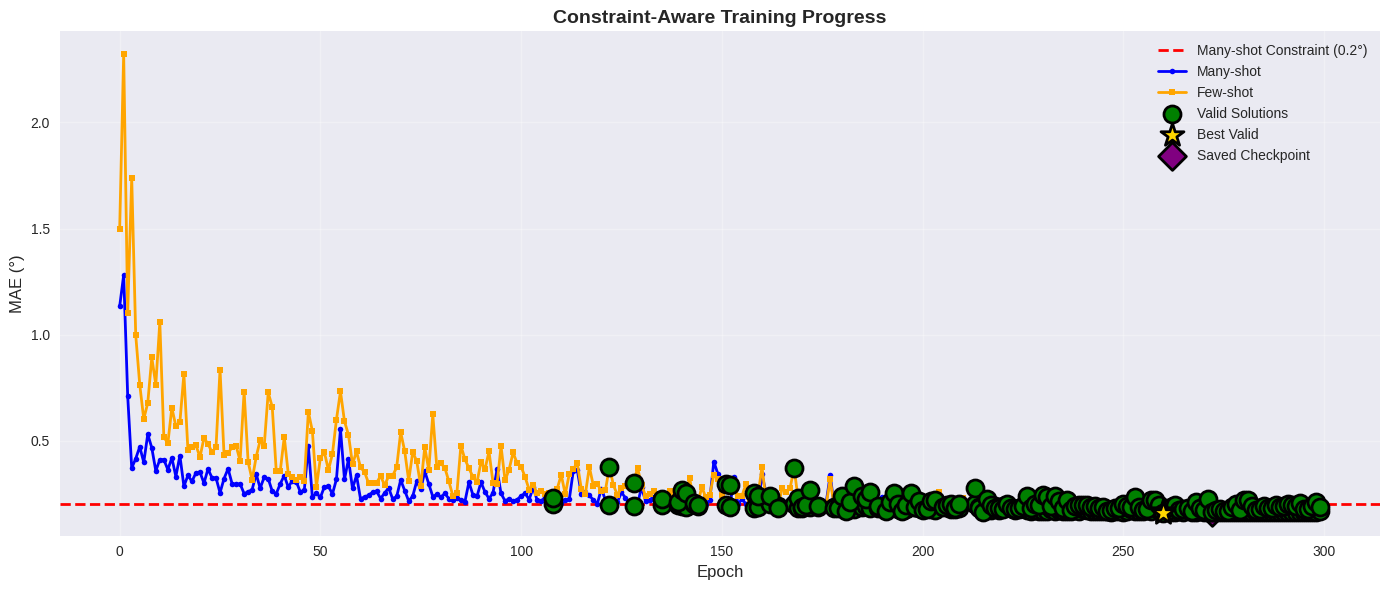

In [48]:
# ============================================================================
# CONSTRAINT-AWARE ANALYSIS
# ============================================================================

print(f"\n{'='*80}")
print(f"CONSTRAINT-AWARE ANALYSIS")
print(f"{'='*80}")

# Find all epochs that meet the constraint
valid_epochs = [i for i, m in enumerate(bucket_many) if m <= CONFIG['MANY_SHOT_CONSTRAINT']]

if valid_epochs:
    print(f"✅ Found {len(valid_epochs)} epochs meeting constraint (Many ≤ {CONFIG['MANY_SHOT_CONSTRAINT']}°)")
    
    # Find best valid solution (minimize few-shot among valid epochs)
    best_valid_idx = min(valid_epochs, key=lambda i: bucket_few[i])
    
    print(f"\n🏆 BEST VALID SOLUTION:")
    print(f"   Epoch: {best_valid_idx + 1}")
    print(f"   Many:   {bucket_many[best_valid_idx]:.4f}° ✅")
    print(f"   Medium: {bucket_medium[best_valid_idx]:.4f}°")
    print(f"   Few:    {bucket_few[best_valid_idx]:.4f}°")
    print(f"   Val Loss: {val_curve[best_valid_idx]:.5f}")
    print(f"   Val MAE:  {val_mae_curve[best_valid_idx]:.5f}°")
    
    # Compare with actual best checkpoint
    print(f"\n📊 COMPARISON WITH SAVED CHECKPOINT:")
    print(f"   Saved Epoch: {best_epoch + 1}")
    print(f"   Many:   {bucket_many[best_epoch]:.4f}° {'✅' if bucket_many[best_epoch] <= CONFIG['MANY_SHOT_CONSTRAINT'] else '❌'}")
    print(f"   Medium: {bucket_medium[best_epoch]:.4f}°")
    print(f"   Few:    {bucket_few[best_epoch]:.4f}°")
    
    if best_valid_idx != best_epoch:
        print(f"\n⚠️  WARNING: Best checkpoint does not meet constraint!")
        print(f"   Consider retraining with adjusted weights.")
else:
    print(f"❌ NO epochs met the constraint (Many ≤ {CONFIG['MANY_SHOT_CONSTRAINT']}°)")
    print(f"   Best Many-shot MAE achieved: {min(bucket_many):.4f}° at epoch {bucket_many.index(min(bucket_many)) + 1}")
    print(f"   Gap to constraint: {min(bucket_many) - CONFIG['MANY_SHOT_CONSTRAINT']:.4f}°")
    print(f"\n💡 RECOMMENDATIONS:")
    print(f"   1. Increase LOSS_WEIGHTS[0] (many-shot) to 1.5 or 2.0")
    print(f"   2. Reduce FOCAL_GAMMA to focus less on hard samples")
    print(f"   3. Reduce LDS_SIGMA for less smoothing")

print(f"{'='*80}\n")

# Plot constraint analysis
fig, ax = plt.subplots(figsize=(14, 6))

# Plot constraint line
ax.axhline(y=CONFIG['MANY_SHOT_CONSTRAINT'], color='red', linestyle='--', linewidth=2, 
           label=f'Many-shot Constraint ({CONFIG["MANY_SHOT_CONSTRAINT"]}°)', zorder=1)

# Plot bucket MAE
ax.plot(bucket_many, label='Many-shot', color='blue', linewidth=2, marker='o', markersize=4, zorder=2)
ax.plot(bucket_few, label='Few-shot', color='orange', linewidth=2, marker='s', markersize=4, zorder=2)

# Highlight valid epochs
if valid_epochs:
    valid_many = [bucket_many[i] for i in valid_epochs]
    valid_few = [bucket_few[i] for i in valid_epochs]
    ax.scatter(valid_epochs, valid_many, color='green', s=150, zorder=5, 
               label='Valid Solutions', edgecolors='black', linewidths=2)
    ax.scatter(valid_epochs, valid_few, color='green', s=150, zorder=5, 
               edgecolors='black', linewidths=2)
    
    # Highlight best valid solution
    ax.scatter([best_valid_idx], [bucket_many[best_valid_idx]], color='gold', s=300, 
               zorder=6, marker='*', edgecolors='black', linewidths=2, label='Best Valid')
    ax.scatter([best_valid_idx], [bucket_few[best_valid_idx]], color='gold', s=300, 
               zorder=6, marker='*', edgecolors='black', linewidths=2)

# Highlight best checkpoint
ax.scatter([best_epoch], [bucket_many[best_epoch]], color='purple', s=200, 
           zorder=4, marker='D', edgecolors='black', linewidths=2, label='Saved Checkpoint')

ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('MAE (°)', fontsize=12)
ax.set_title('Constraint-Aware Training Progress', fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [49]:
checkpoint = torch.load(CONFIG['CHECKPOINT_NAME'], map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.to(device).eval()

print(f"✓ Loaded checkpoint: {CONFIG['CHECKPOINT_NAME']}")
print(f"  Epoch: {checkpoint['epoch']+1}")
print(f"  Val Loss: {checkpoint['val_loss']:.5f}")
print(f"  Val MAE: {checkpoint['val_mae']:.5f}")

# Handle different bucket stat keys based on loss type
bucket_stats = checkpoint['bucket_stats']
if 'mae_many' in bucket_stats:
    print(f"  Many:   {bucket_stats['mae_many']:.4f}°")
    print(f"  Medium: {bucket_stats['mae_medium']:.4f}°")
    print(f"  Few:    {bucket_stats['mae_few']:.4f}°")
else:
    print(f"  Many:   {bucket_stats['mae_b0']:.4f}°")
    print(f"  Medium: {bucket_stats['mae_b1']:.4f}°")
    print(f"  Few:    {bucket_stats['mae_b2']:.4f}°")

✓ Loaded checkpoint: best_modelv4.pth
  Epoch: 273
  Val Loss: 0.14649
  Val MAE: 0.16648
  Many:   0.1657°
  Medium: 0.1777°
  Few:    0.1616°


In [50]:
# ============================================================================
# VALIDATION VERIFICATION
# ============================================================================

model.eval()
running_val_loss, running_val_mae = 0.0, 0.0

with torch.no_grad():
    for xv, yv in val_dataloader:
        xv = xv.to(device).float()
        yv = yv.to(device).float().reshape(-1, 1)
        pred_val = model(xv)
        val_loss = criterion(pred_val, yv)
        running_val_loss += val_loss.item()
        running_val_mae += (pred_val - yv).abs().mean().item()

avg_val_loss = running_val_loss / len(val_dataloader)
avg_val_mae = running_val_mae / len(val_dataloader)

print(f"{'='*80}")
print(f"VALIDATION VERIFICATION")
print(f"{'='*80}")
print(f"Val Loss: {avg_val_loss:.5f}")
print(f"Val MAE:  {avg_val_mae:.5f}°")
print(f"{'='*80}\n")

VALIDATION VERIFICATION
Val Loss: 0.14951
Val MAE:  0.16643°



In [51]:
# ============================================================================
# VISUALIZE PREDICTIONS ON TRAINING DATA
# ============================================================================

print("Loading complete training data (unshuffled) for visualization...")
train_dataloader_unshuffled = load_test_data(
    test_path=CONFIG['TRAIN_PATH'],
    batchsize=CONFIG['BATCH_SIZE'],
    pipeline=pipeline,
    load_anonymized_data=False  # We have ground truth
)

model.eval()
total_loss = 0
preds = []
ground_truths = []

with torch.no_grad():
    for step, (x, y) in enumerate(train_dataloader_unshuffled):
        x, y = x.to(device), y.to(device).reshape(-1, 1)
        pred = model(x)
        loss = criterion(pred, y)
        total_loss += loss.item()
        
        preds.append(pred.cpu().numpy())
        ground_truths.append(y.cpu().numpy())

avg_loss = total_loss / len(train_dataloader_unshuffled)
ground_truths = np.concatenate(ground_truths).flatten()
preds = np.concatenate(preds).flatten()

print(f"Avg Loss on Training Data: {avg_loss:.5f}")
print(f"MAE: {np.mean(np.abs(ground_truths - preds)):.5f}°")
print(f"Predictions shape: {preds.shape}\n")

# Interactive Plotly visualization
fig = go.Figure()
fig.add_trace(go.Scatter(y=ground_truths, mode='lines', name='Ground Truth', 
                         line=dict(color='blue', width=1)))
fig.add_trace(go.Scatter(y=preds, mode='lines', name='Predictions', 
                         line=dict(color='red', width=1), opacity=0.7))
fig.update_layout(
    title='Training Data: Ground Truth vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (°)',
    width=CONFIG['PLOTLY_WIDTH'],
    height=CONFIG['PLOTLY_HEIGHT']
)
fig.show()

Loading complete training data (unshuffled) for visualization...
../datasets_challenge/train/train_part_001.csv
../datasets_challenge/train/train_part_002.csv
../datasets_challenge/train/train_part_003.csv
../datasets_challenge/train/train_part_004.csv
../datasets_challenge/train/train_part_005.csv
../datasets_challenge/train/train_part_006.csv
../datasets_challenge/train/train_part_007.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_008.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_011.csv
../datasets_challenge/train/train_part_012.csv
../datasets_challenge/train/train_part_013.csv
../datasets_challenge/train/train_part_014.csv
../datasets_challenge/train/train_part_009.csv
../datasets_challenge/train/train_part_010.csv
../datasets_challenge/train/train_part_011.csv
../datasets_challenge/train/train_part_012.csv
../datasets_challenge/train/train_part_013

In [52]:
# ============================================================================
# EVALUATE WITH CHALLENGE METRIC
# ============================================================================

print("Evaluating with official challenge metric...\n")

# Load distribution for band mapping
dist_df = pd.read_csv(CONFIG['DIST_CSV'])
shot_band_mapping = dist_df.set_index("sideSlip")["band"].to_dict()

# Create ground truth dataframe
gt_df = pd.DataFrame({"ground_truth_sideslip": ground_truths}, dtype=np.float64)
gt_df["id"] = range(len(ground_truths))
gt_df["band"] = gt_df["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")

# Create predictions dataframe
preds_df = pd.DataFrame({"id": range(len(preds)), "predicted_sideslip": preds})

# Calculate score
score_result = score(gt_df, preds_df, row_id_column_name="id")

print(f"\n{'='*80}")
print(f"CHALLENGE METRIC RESULTS")
print(f"{'='*80}")
print(f"Band Distribution:")
print(gt_df["band"].value_counts())
print(f"{'='*80}\n")

Evaluating with official challenge metric...


CHALLENGE METRIC RESULTS
Band Distribution:
band
many      124956
medium      9521
few         2603
Name: count, dtype: int64



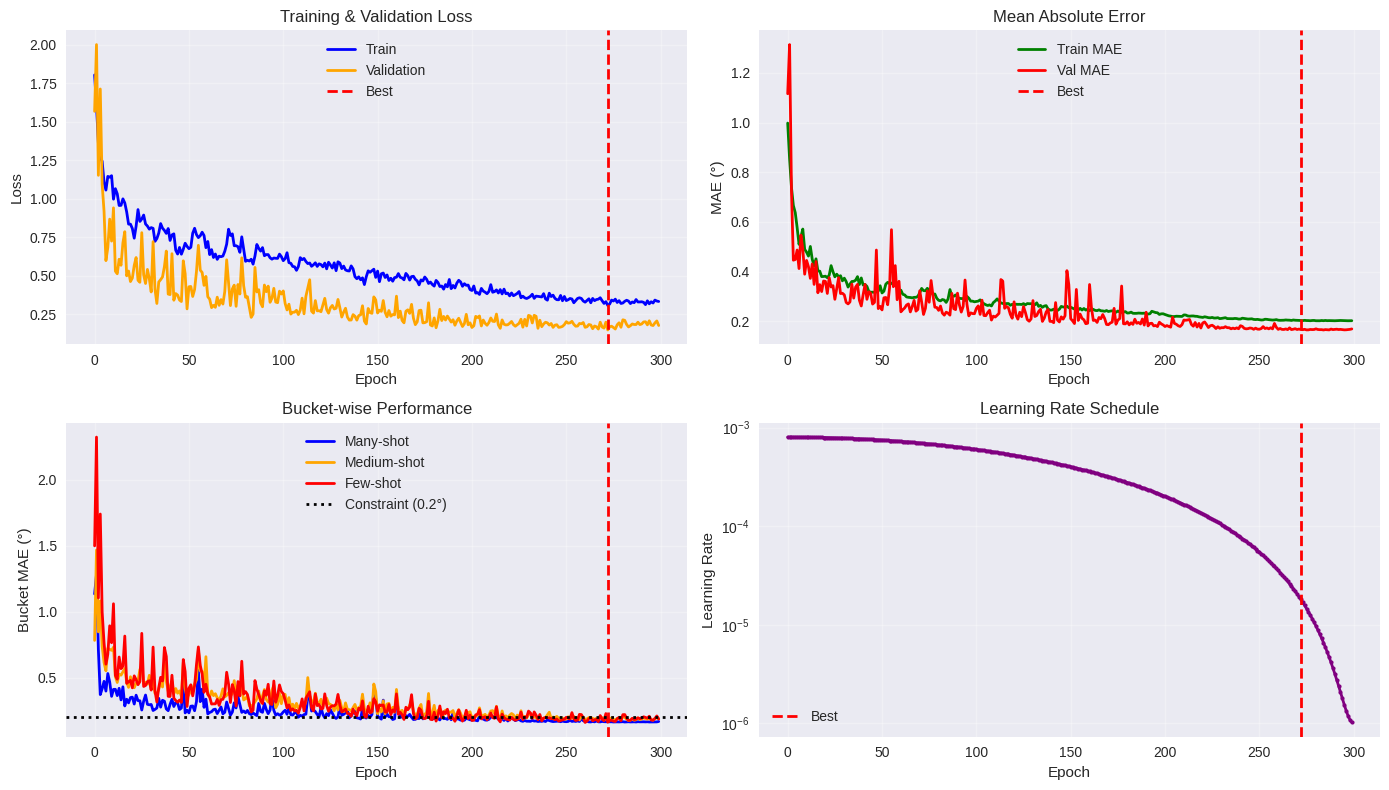


TRAINING SUMMARY - LSTM
Best Epoch: 273/300
Best Val Loss: 0.14649
Best Val MAE: 0.16486
Final LR: 0.000001
Early Stop: No

Bucket MAE at Best Epoch:
  Many-shot:   0.1657°
  Medium-shot: 0.1777°
  Few-shot:    0.1616°



In [53]:
# ============================================================================
# TRAINING VISUALIZATION
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=CONFIG['FIG_SIZE'])

# Loss curves
axes[0, 0].plot(train_curve, label="Train", color='blue', linewidth=2)
axes[0, 0].plot(val_curve, label="Validation", color='orange', linewidth=2)
axes[0, 0].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2, label='Best')
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].set_title("Training & Validation Loss")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# MAE curves
axes[0, 1].plot(train_mae_curve, label="Train MAE", color='green', linewidth=2)
axes[0, 1].plot(val_mae_curve, label="Val MAE", color='red', linewidth=2)
axes[0, 1].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2, label='Best')
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("MAE (°)")
axes[0, 1].set_title("Mean Absolute Error")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Bucket MAE evolution
axes[1, 0].plot(bucket_many, label="Many-shot", color='blue', linewidth=2)
axes[1, 0].plot(bucket_medium, label="Medium-shot", color='orange', linewidth=2)
axes[1, 0].plot(bucket_few, label="Few-shot", color='red', linewidth=2)
axes[1, 0].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2)
axes[1, 0].axhline(y=CONFIG['MANY_SHOT_CONSTRAINT'], color='black', linestyle=':', 
                   linewidth=2, label=f"Constraint ({CONFIG['MANY_SHOT_CONSTRAINT']}°)")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Bucket MAE (°)")
axes[1, 0].set_title("Bucket-wise Performance")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Learning rate schedule
axes[1, 1].plot(learning_rate_curve, color='purple', linewidth=2, marker='o', markersize=3)
axes[1, 1].axvline(x=best_epoch, color='red', linestyle='--', linewidth=2, label='Best')
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Learning Rate")
axes[1, 1].set_title("Learning Rate Schedule")
axes[1, 1].set_yscale('log')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Training summary
print(f"\n{'='*80}")
print(f"TRAINING SUMMARY - {CONFIG['MODEL_TYPE']}")
print(f"{'='*80}")
print(f"Best Epoch: {best_epoch + 1}/{len(train_curve)}")
print(f"Best Val Loss: {min(val_curve):.5f}")
print(f"Best Val MAE: {min(val_mae_curve):.5f}")
print(f"Final LR: {learning_rate_curve[-1]:.6f}")
print(f"Early Stop: {'Yes' if len(train_curve) < CONFIG['NUM_EPOCHS'] else 'No'}")
print(f"\nBucket MAE at Best Epoch:")
print(f"  Many-shot:   {bucket_many[best_epoch]:.4f}°")
print(f"  Medium-shot: {bucket_medium[best_epoch]:.4f}°")
print(f"  Few-shot:    {bucket_few[best_epoch]:.4f}°")
print(f"{'='*80}\n")

In [54]:
# ============================================================================
# GENERATE PREDICTIONS
# ============================================================================

print(f"\nLoading test data from: {CONFIG['TEST_PATH']}")
test_dataloader = load_test_data(
    test_path=CONFIG['TEST_PATH'],
    batchsize=CONFIG['BATCH_SIZE'],
    pipeline=pipeline,
    load_anonymized_data=True,
)

print(f"Generating predictions...")
model.eval()
test_preds = []

with torch.no_grad():
    for x, y in test_dataloader:
        x = x.to(device)
        pred = model(x)
        test_preds.append(pred.cpu().numpy())

test_preds = np.concatenate(test_preds).flatten()

print(f"\n✓ Generated {len(test_preds)} predictions")
print(f"  Range: [{test_preds.min():.2f}°, {test_preds.max():.2f}°]")
print(f"  Mean: {test_preds.mean():.3f}° | Std: {test_preds.std():.3f}°")

# Sanity checks
assert len(test_preds) > 0, "No predictions generated!"
assert not np.isnan(test_preds).any(), "NaN values in predictions!"
assert not np.isinf(test_preds).any(), "Inf values in predictions!"
print("✓ Predictions passed sanity checks")


Loading test data from: ../datasets_challenge/test
../datasets_challenge/test/test_part_001.csv
../datasets_challenge/test/test_part_002.csv
../datasets_challenge/test/test_part_003.csv
../datasets_challenge/test/test_part_004.csv
../datasets_challenge/test/test_part_005.csv
../datasets_challenge/test/test_part_006.csv
../datasets_challenge/test/test_part_007.csv
../datasets_challenge/test/test_part_008.csv
../datasets_challenge/test/test_part_009.csv
../datasets_challenge/test/test_part_010.csv
../datasets_challenge/test/test_part_011.csv
Generating predictions...
Generating predictions...

✓ Generated 49328 predictions
  Range: [-7.94°, 9.64°]
  Mean: 0.003° | Std: 1.455°
✓ Predictions passed sanity checks

✓ Generated 49328 predictions
  Range: [-7.94°, 9.64°]
  Mean: 0.003° | Std: 1.455°
✓ Predictions passed sanity checks


In [55]:


test_ground_truths = []
with torch.no_grad():
    for x, y in test_dataloader:
        test_ground_truths.append(y.numpy())
test_ground_truths = np.concatenate(test_ground_truths)

fig = go.Figure()
fig.add_trace(go.Scatter(y=test_ground_truths, mode='lines', name='Placeholder (zeros)', 
                         line=dict(color='blue', width=1)))
fig.add_trace(go.Scatter(y=test_preds.flatten(), mode='lines', name='Predictions', 
                         line=dict(color='red', width=1), opacity=0.7))
fig.update_layout(
    title='Test Set Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (°)',
    width=CONFIG['PLOTLY_WIDTH'],
    height=CONFIG['PLOTLY_HEIGHT']
)
fig.show()

In [56]:


y_pred = pd.DataFrame({
    "id": range(len(test_preds)),
    "predicted_sideslip": test_preds
})

y_pred.to_csv(CONFIG['SUBMISSION_CSV'], index=False)

print(f"✅ Predictions saved to: {CONFIG['SUBMISSION_CSV']}")
print(f"   Total samples: {len(test_preds)}")
print(f"   Ready for submission!")

✅ Predictions saved to: predictions4.csv
   Total samples: 49328
   Ready for submission!


In [57]:
# ============================================================================
# EVALUATE TRAINING PREDICTIONS WITH CHALLENGE METRIC
# ============================================================================

print("Evaluating training predictions with official challenge metric...\n")

# Create ground truth dataframe
gt_df = pd.DataFrame({"ground_truth_sideslip": ground_truths}, dtype=np.float64)
gt_df["id"] = range(len(ground_truths))
gt_df["band"] = gt_df["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")

# Create predictions dataframe
preds_df = pd.DataFrame({"id": range(len(preds)), "predicted_sideslip": preds})

# Calculate score
score_result = score(gt_df, preds_df, row_id_column_name="id")

print(f"\n{'='*80}")
print(f"CHALLENGE METRIC RESULTS (Training Data)")
print(f"{'='*80}")
print(f"Overall Score: {score_result}")
print(f"\nBand Distribution:")
print(gt_df["band"].value_counts())
print(f"{'='*80}\n")

Evaluating training predictions with official challenge metric...


CHALLENGE METRIC RESULTS (Training Data)
Overall Score: band
few       0.14330
many      0.16084
medium    0.15964
Name: L1, dtype: float64

Band Distribution:
band
many      124956
medium      9521
few         2603
Name: count, dtype: int64

